In [1]:
import photonforge as pf
import siepic_forge as siepic
from photonforge.live_viewer import LiveViewer

tech = siepic.ebeam()
pf.config.default_technology = tech

PORTA = 8765
if "viewer" in globals():
    viewer.stop()

viewer = LiveViewer(port=PORTA)


def mostrar(componente):
    return viewer(componente)


print(f"{tech.name} {tech.version}")
print(f"LiveViewer: http://localhost:{viewer.port}")

15:51:28 Hora oficial do Brasil WARNING: Using canonical configuration directory
                                at 'C:\Users\José Roberto\.config\tidy3d'. Found
                                legacy directory at 'C:\Users\José              
                                Roberto\.tidy3d', which will be ignored. Tidy3D 
                                configuration now uses 'C:\Users\José           
                                Roberto\.config\tidy3d\config.toml'.            

<frozen importlib._bootstrap>:488: RuntimeWarning: Unable to write to C:\Users\José Roberto\.config\tidy3d\td-ddea8e2864cc6b3b58bd6ce30fef6531268ef7da1f2ebf7864f3c600bf3f4a4e.auth.


LiveViewer started at http://localhost:8765
SiEPIC EBeam Si 1.2.2
LiveViewer: http://localhost:8765


## Escrever em silício

In [2]:
@pf.parametric_component
def caractere(*, texto: str = "A", tamanho: float = 10.0) -> pf.Component:
    """Desenha um texto ASCII na camada de silício (1/0)."""
    texto_str = str(texto)
    if not texto_str.strip():
        raise ValueError("texto não pode ser vazio")
    tamanho_um = float(tamanho)
    if tamanho_um * 0.025 < 0.06:
        raise ValueError("Podem existir guias separados por menos de 60 nm.") # O traço mais fino da fonte do PhotonForge mede 2,5% dessa altura.

    componente = pf.Component(f"char_{texto_str}")
    componente.add("Si", *pf.text(texto_str, tamanho_um, typeface=1))
    return componente

In [3]:
teste = caractere(texto="ABC-_-0123")
mostrar(teste)
print(teste.name)
print("bounds (µm):", teste.bounds())
teste

char_ABC-_-0123
bounds (µm): (array([0., 2.]), array([57.6,  8.5]))


In [4]:
LADO_UM = 9000.0
LIMITE_UM = LADO_UM / 2.0
_LADOS = ("esquerda", "direita", "cima", "baixo")


def _ancora_do_bloco(limites, lado: str) -> tuple[float, float]:
    """Meio da lateral escolhida do bloco de texto, em µm."""
    (x_min, y_min), (x_max, y_max) = limites
    x_meio = (float(x_min) + float(x_max)) / 2.0
    y_meio = (float(y_min) + float(y_max)) / 2.0
    if lado == "esquerda":
        return float(x_min), y_meio
    if lado == "direita":
        return float(x_max), y_meio
    if lado == "cima":
        return x_meio, float(y_max)
    return x_meio, float(y_min)


@pf.parametric_component
def texto_posicionado(
    *,
    texto: str = "A",
    tamanho: float = 10.0,
    coordenada: tuple[float, float] = (0.0, 0.0),
    posicao: str = "esquerda",
) -> pf.Component:
    
    x = float(coordenada[0])
    y = float(coordenada[1])
    if abs(x) > LIMITE_UM or abs(y) > LIMITE_UM:
        raise ValueError(
            f"coordenada ({x:g}, {y:g}) µm fora do quadrado de "
            f"{LADO_UM:g}×{LADO_UM:g} µm com centro na origem "
            f"(limites ±{LIMITE_UM:g} µm)"
        )

    lado = str(posicao).strip().lower()
    if lado not in _LADOS:
        raise ValueError("posicao deve ser esquerda, direita, cima ou baixo")

    bloco = caractere(texto=texto, tamanho=tamanho)
    ancora_x, ancora_y = _ancora_do_bloco(bloco.bounds(), lado)

    componente = pf.Component(f"texto_{lado}")
    referencia = componente.add_reference(bloco)
    referencia.translate((x - ancora_x, y - ancora_y))

    (x0, y0), (x1, y1) = componente.bounds()
    if (
        float(x0) < -LIMITE_UM
        or float(y0) < -LIMITE_UM
        or float(x1) > LIMITE_UM
        or float(y1) > LIMITE_UM
    ):
        raise ValueError(
            "o bloco de texto ultrapassa o quadrado de "
            f"{LADO_UM:g}×{LADO_UM:g} µm "
            f"(limites do texto: ({float(x0):.2f}, {float(y0):.2f}) a "
            f"({float(x1):.2f}, {float(y1):.2f}) µm)"
        )
    return componente

I0-M1: esquerda em (2200.0, -2900.0) µm
I0
M1
GC2: direita em (950.0, -3134.0) µm


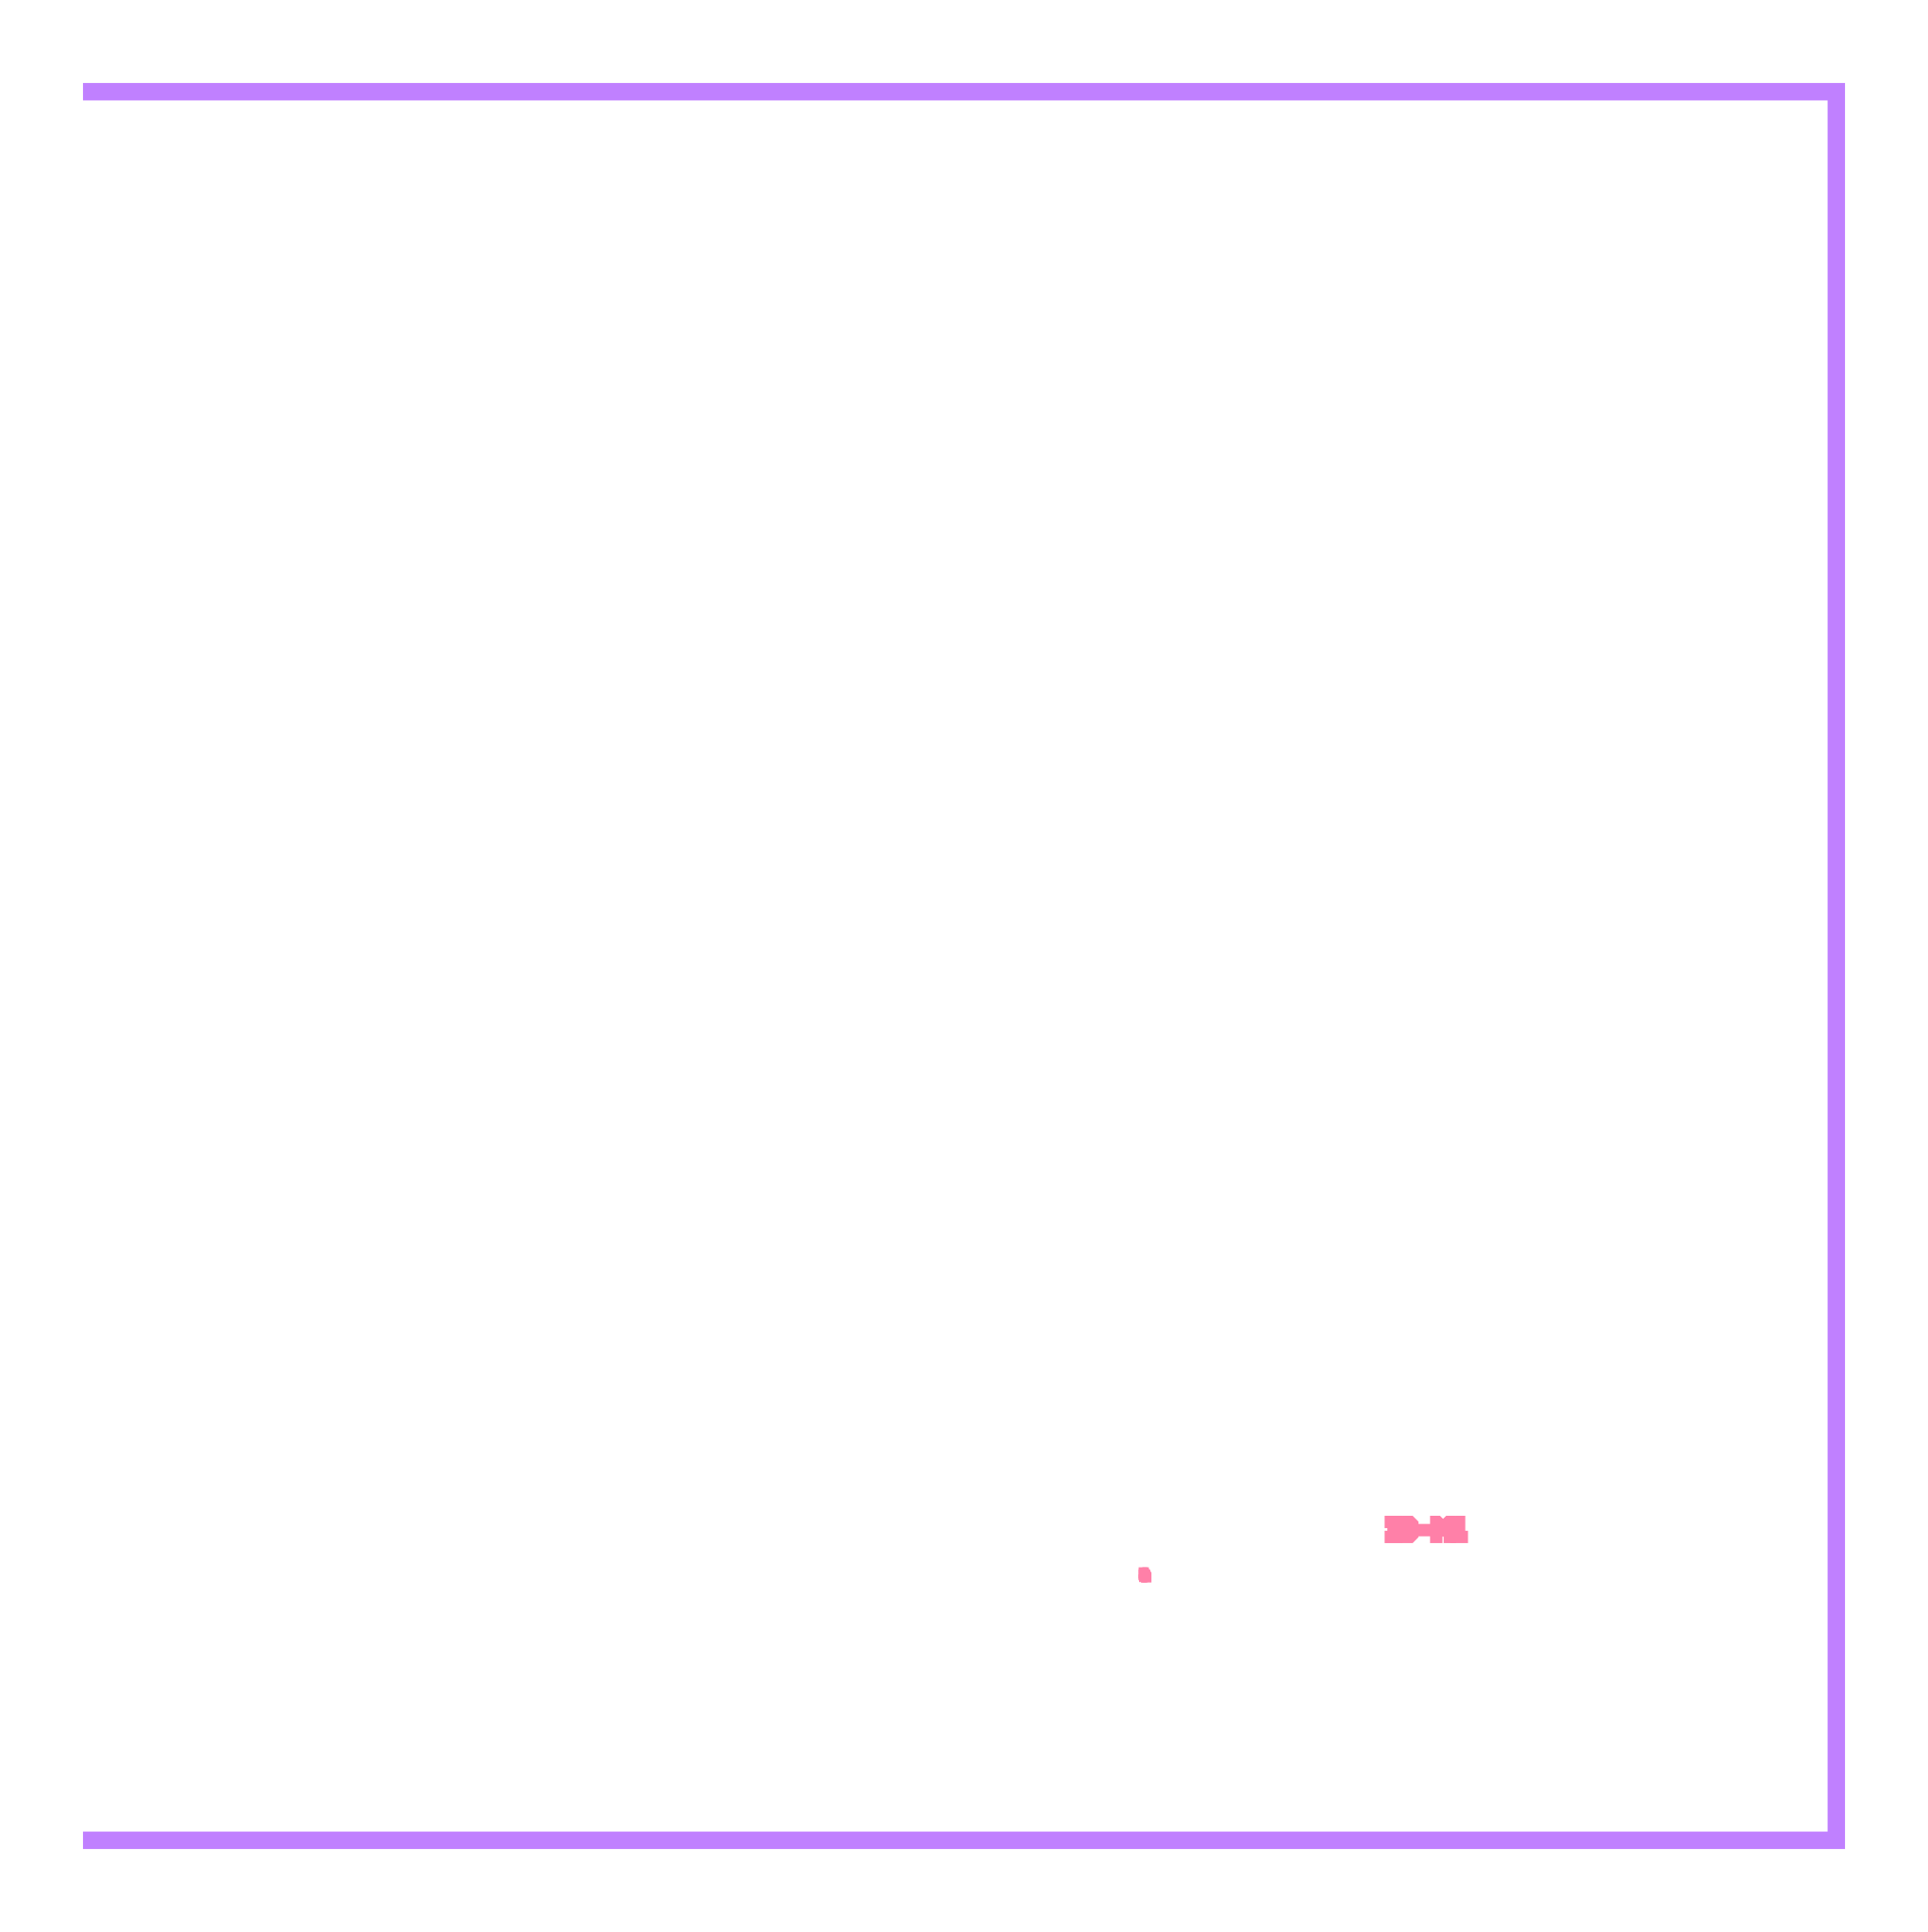

In [5]:
exemplos = [
    texto_posicionado(texto="I0-M1", tamanho=140, coordenada=(2200, -2900), posicao="esquerda"),
    texto_posicionado(texto="I0\nM1\nGC2", tamanho=10, coordenada=(950, -3134), posicao="direita"),
    #texto_posicionado(texto="CIMA", tamanho=400, coordenada=(0, 0), posicao="cima"),
    #texto_posicionado(texto="BAIXO", tamanho=400, coordenada=(0, 0), posicao="baixo"),
]

vitrine = pf.Component("textos_no_quadrado")
moldura = pf.Path((-LIMITE_UM, -LIMITE_UM), width=40)
moldura.segment(
    [
        (LIMITE_UM, -LIMITE_UM),
        (LIMITE_UM, LIMITE_UM),
        (-LIMITE_UM, LIMITE_UM),
        (-LIMITE_UM, -LIMITE_UM),
    ]
)
vitrine.add("Floor Plan-Not Fabricated", moldura)
for exemplo in exemplos:
    vitrine.add_reference(exemplo)

mostrar(vitrine)
for exemplo in exemplos:
    pedido = exemplo.parametric_kwargs
    x, y = _ancora_do_bloco(exemplo.bounds(), pedido["posicao"])
    print(f"{pedido['texto']}: {pedido['posicao']} em ({x:.1f}, {y:.1f}) µm")
vitrine

In [6]:
from pathlib import Path

layout_gds = vitrine.copy()
layout_gds.filter_layers(["Floor Plan-Not Fabricated"], keep=False)
layout_gds.add(
    "Text",
    pf.Label("", origin=(-LIMITE_UM, -LIMITE_UM)),
    pf.Label("", origin=(LIMITE_UM, LIMITE_UM)),
)

pasta = Path("tag-layout")
if not pasta.is_dir():
    pasta = Path(".")
destino = pasta / "textos_no_quadrado.gds"
pf.write_layout(destino, layout_gds)

conferido = pf.load_layout(destino, technology=tech)[layout_gds.name]
print(destino.resolve())
print("bounds do GDS (µm):", conferido.bounds())
print("silício (µm):", conferido.bounds(layers=["Si"]))
print("camadas:", sorted(conferido.layers(include_dependencies=True)))
print(
    "floorplan:",
    conferido.get_structures(layer="Floor Plan-Not Fabricated"),
)


C:\repositories\colab_layout_02\colab-layout\tag-layout\textos_no_quadrado.gds
bounds do GDS (µm): (array([-4500., -4500.]), array([4500., 4500.]))
silício (µm): (array([  933.7 , -3148.25]), array([ 2579.4, -2854.5]))
camadas: [(1, 0), (10, 0)]
floorplan: []


I0-M1: esquerda em (2200.0, -2900.0) µm
  MZI com dados do FDTD
GC
1: direita em (950.0, -3134.0) µm
C:\repositories\colab_layout_02\colab-layout\tag-layout\textos_no_quadrado.gds
bounds do GDS (µm): (array([-4500., -4500.]), array([4500., 4500.]))
silício (µm): (array([  939.6 , -3142.75]), array([ 2579.4, -2854.5]))
camadas: [(1, 0), (10, 0)]
floorplan: []


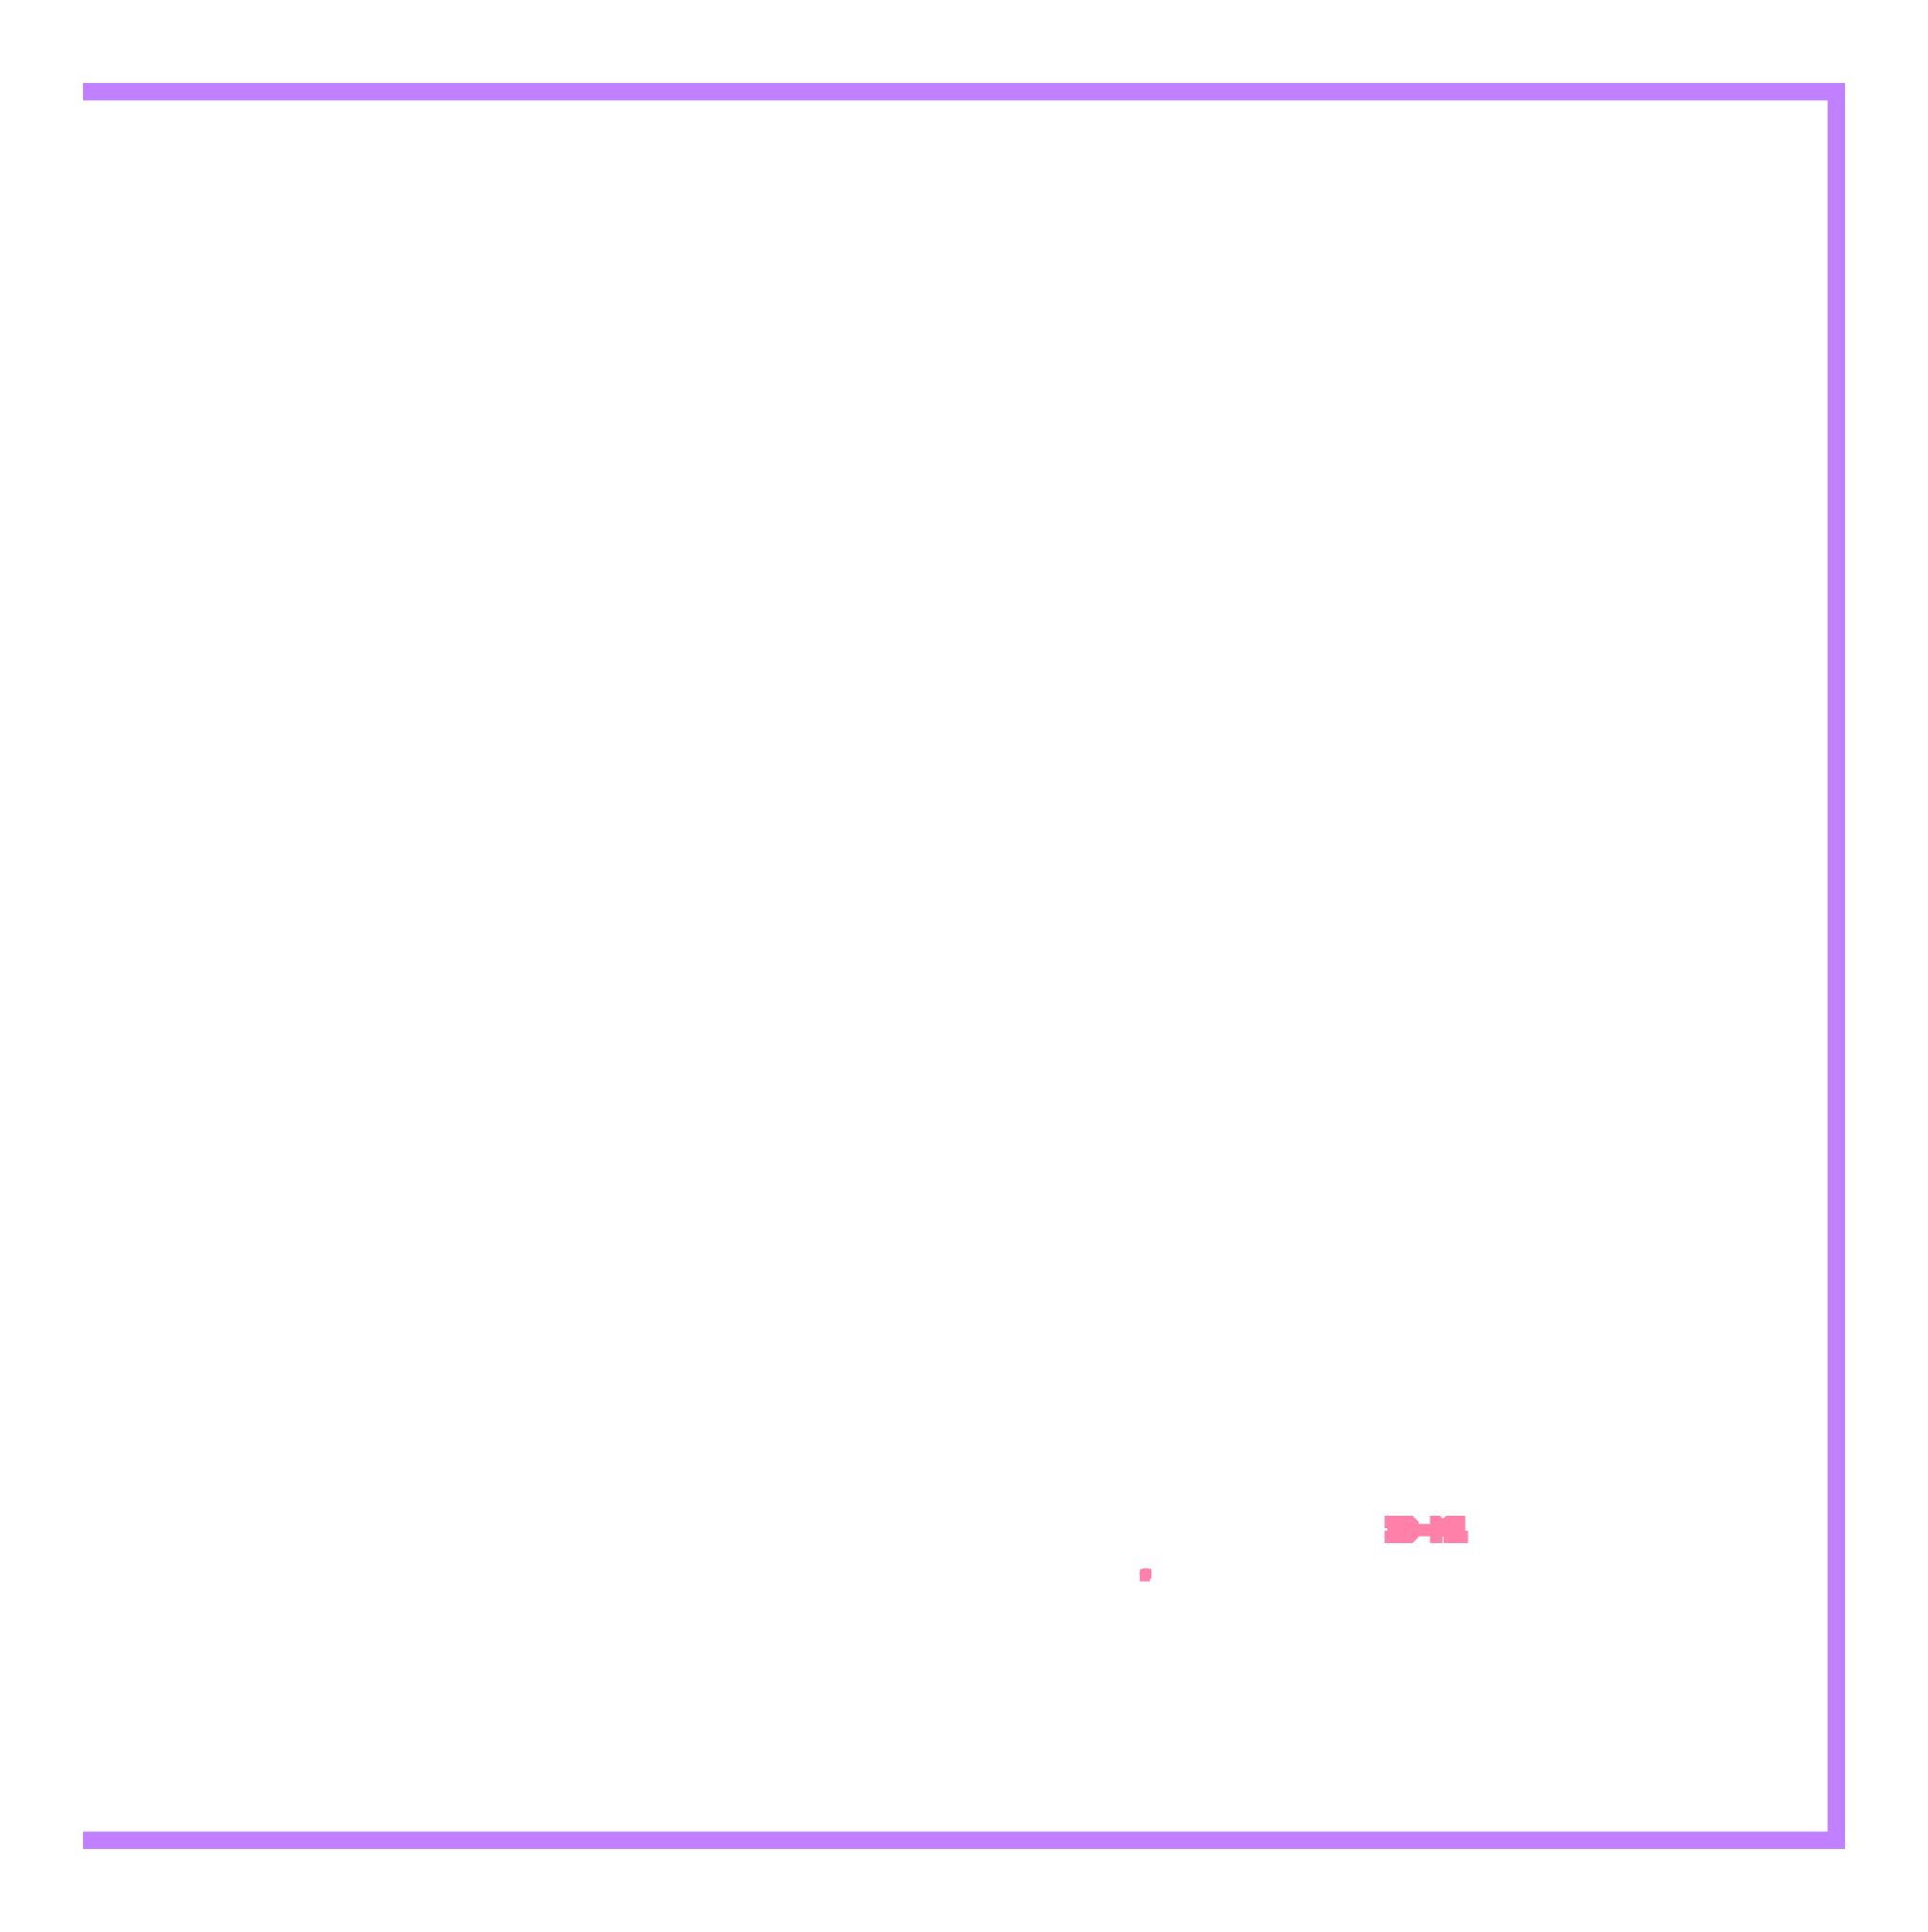

In [8]:
import csv
from pathlib import Path


def textos_do_csv(caminho=None):
    """Lê o CSV de tags, posiciona os textos no quadrado e grava o GDS."""
    if caminho is None:
        pasta = Path("tag-layout")
        if not pasta.is_dir():
            pasta = Path(".")
        caminho = pasta / "tags.csv"
    else:
        caminho = Path(caminho)

    with caminho.open(newline="", encoding="utf-8-sig") as arquivo:
        leitor = csv.DictReader(arquivo, skipinitialspace=True)
        pedidos = []
        for linha in leitor:
            texto = (linha.get("TAG") or "").strip().replace("\\n", "\n")
            if not texto:
                continue
            pedidos.append(
                {
                    "texto": texto,
                    "tamanho": float(linha["SIZE"]),
                    "coordenada": (float(linha["COORDX"]), float(linha["COORDY"])),
                    "posicao": (linha.get("POS") or "").strip(),
                    "rotulo": (linha.get("LABEL") or "").strip(),
                }
            )

    if not pedidos:
        raise ValueError(f"nenhum texto em {caminho}")

    exemplos = [
        texto_posicionado(
            texto=pedido["texto"],
            tamanho=pedido["tamanho"],
            coordenada=pedido["coordenada"],
            posicao=pedido["posicao"],
        )
        for pedido in pedidos
    ]

    vitrine = pf.Component("textos_no_quadrado")
    moldura = pf.Path((-LIMITE_UM, -LIMITE_UM), width=40)
    moldura.segment(
        [
            (LIMITE_UM, -LIMITE_UM),
            (LIMITE_UM, LIMITE_UM),
            (-LIMITE_UM, LIMITE_UM),
            (-LIMITE_UM, -LIMITE_UM),
        ]
    )
    vitrine.add("Floor Plan-Not Fabricated", moldura)
    for exemplo in exemplos:
        vitrine.add_reference(exemplo)

    mostrar(vitrine)
    for exemplo, pedido in zip(exemplos, pedidos):
        kwargs = exemplo.parametric_kwargs
        x, y = _ancora_do_bloco(exemplo.bounds(), kwargs["posicao"])
        print(f"{kwargs['texto']}: {kwargs['posicao']} em ({x:.1f}, {y:.1f}) µm")
        if pedido["rotulo"]:
            print(f"  {pedido['rotulo']}")

    layout_gds = vitrine.copy()
    layout_gds.filter_layers(["Floor Plan-Not Fabricated"], keep=False)
    layout_gds.add(
        "Text",
        pf.Label("", origin=(-LIMITE_UM, -LIMITE_UM)),
        pf.Label("", origin=(LIMITE_UM, LIMITE_UM)),
    )

    destino = caminho.parent / "textos_no_quadrado.gds"
    pf.write_layout(destino, layout_gds)

    conferido = pf.load_layout(destino, technology=tech)[layout_gds.name]
    print(destino.resolve())
    print("bounds do GDS (µm):", conferido.bounds())
    print("silício (µm):", conferido.bounds(layers=["Si"]))
    print("camadas:", sorted(conferido.layers(include_dependencies=True)))
    print(
        "floorplan:",
        conferido.get_structures(layer="Floor Plan-Not Fabricated"),
    )
    return vitrine


vitrine = textos_do_csv()
vitrine
